# Eigenstates of the cosine GKP Hamiltonian

We study
$$
\hat{H} = 2 - \left[\cos\hat{p} + \cos(2\pi n\hat{q})\right],
$$
with $[\hat q, \hat p] = i$. $\cos\hat p$ shifts $\hat q$ by $\pm 1$ and $\cos(2\pi n\hat q)$ shifts $\hat p$ by $\pm 2\pi n$. For integer $n$ these two terms commute, so the $E = 0$ subspace is an $n$-dimensional GKP code with ideal codewords $\ket{j_L} \propto \sum_k \ket{q = k + j/n}$.

Because the two terms commute, $\hat H$ has a continuous spectrum and no normalisable ground state. In a truncated Fock space the low-lying eigenstates are finite-energy GKP states whose envelope is set by the cutoff $N_{\text{fock}}$.

In [32]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import jax.numpy as jnp
import jaxquantum as jqt
from jax.scipy.linalg import expm

from gkp_optimal_control.hamiltonians import gkp_cosine_hamiltonian
from gkp_optimal_control.operators import quadrature_operators
from gkp_optimal_control.plotting import (
    plot_photon_number,
    plot_wigner,
    set_plot_style,
)
from gkp_optimal_control.states import gkp_states

set_plot_style()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## System parameters

Read literally with $\hat q = (\hat a + \hat a^\dagger)/\sqrt{2}$, the lattice is strongly anisotropic: spacing $1/n$ in $q$ and $2\pi$ in $p$. Converging that would take far more photons. We therefore use the canonically rescaled quadratures
$$
\hat q = \hat x / \sqrt{2\pi n}, \qquad \hat p = \sqrt{2\pi n}\, \hat p_x ,
$$
which preserve $[\hat q, \hat p] = i$ and give
$$
\hat H = 2 - \cos(\sqrt{2\pi n}\,\hat p_x) - \cos(\sqrt{2\pi n}\,\hat x).
$$
For $n = 2$ this is the square $\sqrt{\pi}$ lattice built by `gkp_states` with $\alpha = \sqrt{\pi/2}$, $\beta = i\sqrt{\pi/2}$. Set `symmetric = False` to use the literal frame instead.

In [49]:
n_fock = 800      # Fock truncation (sets the finite-energy envelope)
n_code = 2        # code dimension n (2 = GKP qubit)
symmetric = True  # canonically rescaled frame (see above)
n_states = 4      # number of low-lying eigenstates to plot
bound = 7         # phase-space half-width for Wigner plots

## Spectrum

The lowest $n$ eigenstates form a quasi-degenerate band (the code space), separated by a gap from the next band.

Lowest energies: [0.0213 0.0213 0.0528 0.0536 0.0541 0.0542 0.0942 0.0957]


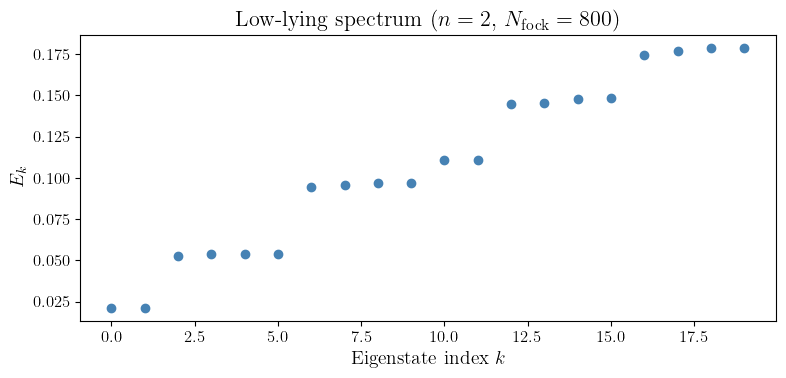

In [50]:
H = gkp_cosine_hamiltonian(n_fock, n=n_code, symmetric=symmetric)
energies, vecs = jnp.linalg.eigh(H)

print("Lowest energies:", np.round(np.asarray(energies[:8]), 4))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(20), np.asarray(energies[:20]), "o", color="steelblue")
ax.set_xlabel("Eigenstate index $k$")
ax.set_ylabel("$E_k$")
ax.set_title(rf"Low-lying spectrum ($n = {n_code}$, $N_{{\rm fock}} = {n_fock}$)")
fig.tight_layout()
plt.show()

## Convergence with the Fock cutoff

Since the true spectrum is continuous, $E_0$ keeps decreasing toward $0$ and $\langle \hat n \rangle$ keeps growing as $N_{\text{fock}}$ increases. The quantity to watch is the population in the last few Fock levels. If it is not small, the state is being clipped by the truncation.

In [51]:
print(f"{'N_fock':>7} {'E0':>8} {'E1':>8} {'E2':>8} {'<n>_0':>8} {'tail_0':>8} {'tail_1':>8}")
for n_test in [40, 60, 80, 100]:
    e_t, v_t = jnp.linalg.eigh(gkp_cosine_hamiltonian(n_test, n=n_code, symmetric=symmetric))
    probs = jnp.abs(v_t[:, :2]) ** 2
    nbar = jnp.sum(jnp.arange(n_test)[:, None] * probs, axis=0)
    tail = jnp.sum(probs[-5:], axis=0)
    print(f"{n_test:>7} {float(e_t[0]):8.4f} {float(e_t[1]):8.4f} {float(e_t[2]):8.4f} "
          f"{float(nbar[0]):8.1f} {float(tail[0]):8.4f} {float(tail[1]):8.4f}")

 N_fock       E0       E1       E2    <n>_0   tail_0   tail_1
     40   0.3482   0.3592   0.6909     10.6   0.0081   0.0018
     60   0.2369   0.2387   0.5205     16.0   0.0297   0.0001
     80   0.1755   0.1977   0.4220     21.7   0.0134   0.0022
    100   0.1473   0.1518   0.3474     26.2   0.0053   0.0074


## Low-lying eigenstates

The truncation splits the code-space degeneracy arbitrarily. The raw eigenstates $\ket{\psi_0}, \ket{\psi_1}$ are therefore superpositions of the logical codewords. $\ket{\psi_2}, \ket{\psi_3}$ belong to the next band: grid states displaced off the code space.

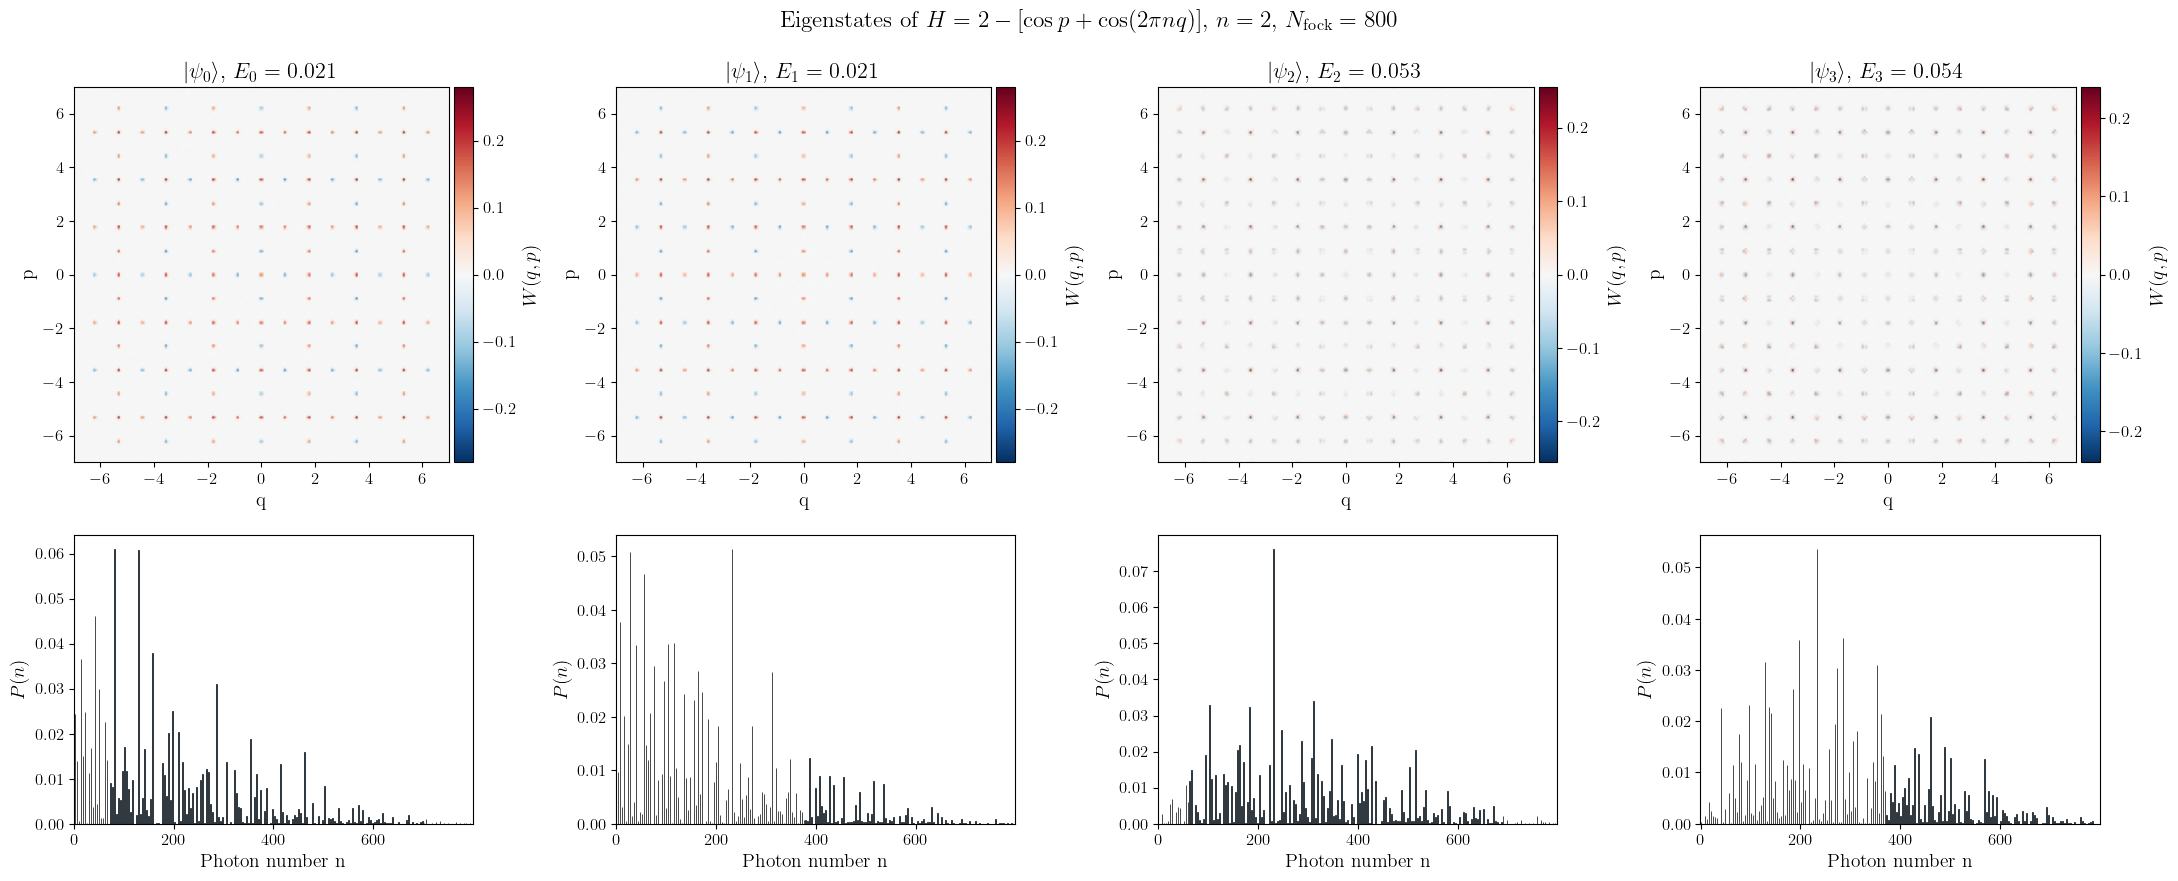

In [52]:
eig_states = [jqt.Qarray.create(vecs[:, k].reshape(n_fock, 1)) for k in range(n_states)]

fig, axes = plt.subplots(2, n_states, figsize=(5.5 * n_states, 9), gridspec_kw={"height_ratios": [1.4, 1]})
for k, state in enumerate(eig_states):
    plot_wigner(state, x_bound=bound, y_bound=bound, ax=axes[0, k],
                title=rf"$\ket{{\psi_{k}}}$, $E_{k} = {float(energies[k]):.3f}$")
    plot_photon_number(state, ax=axes[1, k], max_n=n_fock)

fig.suptitle(rf"Eigenstates of $H = 2 - [\cos p + \cos(2\pi n q)]$, $n = {n_code}$, $N_{{\rm fock}} = {n_fock}$")
fig.tight_layout()
fig.savefig("../../figs/cosine_gkp/eigenstates.pdf", bbox_inches="tight")
plt.show()

## Logical basis inside the ground band

The logical $Z$ operator is $\hat Z_L = e^{2\pi i \hat q}$, which equals $e^{i\sqrt{2\pi/n}\,\hat x}$ in the rescaled frame. It acts on the codewords as $\hat Z_L\ket{j_L} = e^{2\pi i j/n}\ket{j_L}$. Diagonalising $\hat Z_L$ projected onto the lowest $n$ eigenstates gives the logical codewords directly from the Hamiltonian, with no reference states needed. As with the cosines, the exponential is computed in a padded space and cropped.

In [53]:
pad = 3
x_big, _ = quadrature_operators(pad * n_fock)
z_scale = jnp.sqrt(2 * jnp.pi / n_code) if symmetric else 2 * jnp.pi
z_l = expm(1j * z_scale * x_big)[:n_fock, :n_fock]

ground = vecs[:, :n_code]
z_eigs, u = jnp.linalg.eig(ground.conj().T @ z_l @ ground)
# Z_L |j_L> = exp(2 pi i j / n) |j_L>: snap each phase to the nearest label j.
# (Sorting the raw wrapped phase is fragile: the j = 0 eigenvalue sits on the
# branch cut, and a round-off imaginary part of -1e-17 wraps it to ~2 pi.)
labels = jnp.mod(jnp.round(jnp.angle(z_eigs) * n_code / (2 * jnp.pi)), n_code).astype(int)
assert sorted(np.asarray(labels).tolist()) == list(range(n_code)), f"Ambiguous Z_L labels: {labels}"
order = jnp.argsort(labels)  # |0_L>, |1_L>, ...

logical = [jqt.Qarray.create((ground @ u[:, k]).reshape(n_fock, 1)).unit() for k in order]
print("Projected Z_L eigenvalues:", np.round(np.asarray(z_eigs[order]), 3))

Projected Z_L eigenvalues: [ 0.997-0.j -0.997+0.j]


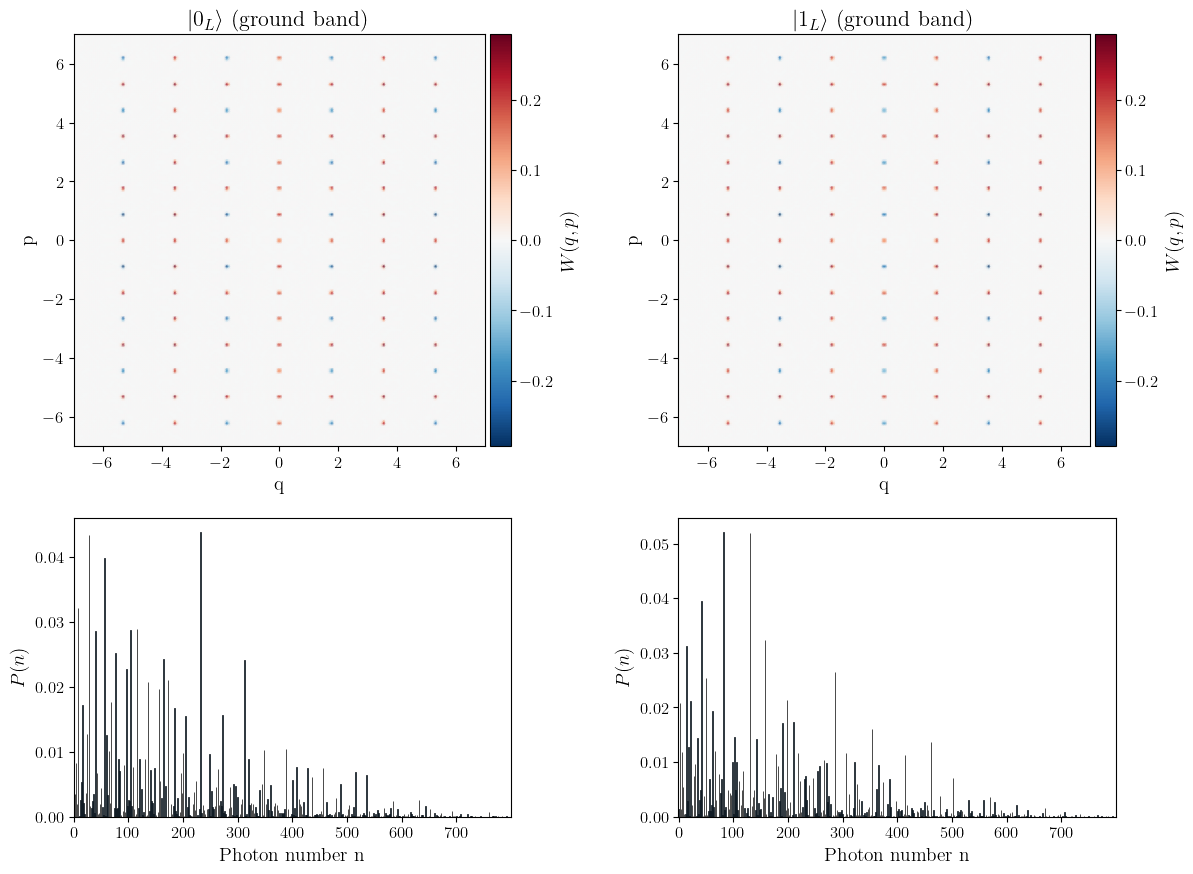

In [54]:
fig, axes = plt.subplots(2, n_code, figsize=(6 * n_code, 9), gridspec_kw={"height_ratios": [1.4, 1]})
for j, state in enumerate(logical):
    plot_wigner(state, x_bound=bound, y_bound=bound, ax=axes[0, j],
                title=rf"$\ket{{{j}_L}}$ (ground band)")
    plot_photon_number(state, ax=axes[1, j], max_n=n_fock)

fig.tight_layout(w_pad=4)
fig.savefig("../../figs/cosine_gkp/logical_states.pdf", bbox_inches="tight")
plt.show()

## Comparison with `gkp_states`

For $n = 2$ in the symmetric frame, the ground band should match the finite-energy square GKP code from `states.gkp_states`. We scan the envelope width $\Delta$, compute the fidelity of each Hamiltonian codeword with the corresponding reference codeword, and keep the best match.

Best Delta = 0.045:  F(0_L) = 0.8237,  F(1_L) = 0.8217


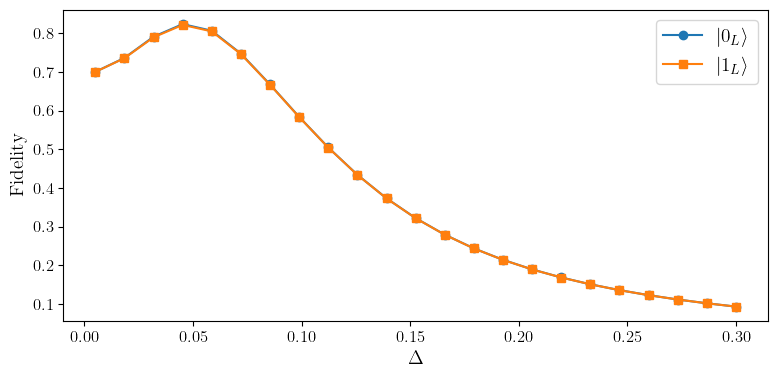

In [55]:
if n_code == 2 and symmetric:
    gkp_alpha = jnp.sqrt(jnp.pi / 2)
    gkp_beta = 1j * jnp.sqrt(jnp.pi / 2)

    deltas = np.linspace(0.005, 0.3, 23)
    fids = []
    for d in deltas:
        ref_0, ref_1 = gkp_states(n_fock, gkp_alpha, gkp_beta, float(d), 10)
        f0 = jnp.abs(jnp.vdot(ref_0.data, logical[0].data)) ** 2
        f1 = jnp.abs(jnp.vdot(ref_1.data, logical[1].data)) ** 2
        fids.append((float(f0), float(f1)))
    fids = np.array(fids)
    best = int(np.argmax(fids.mean(axis=1)))
    best_delta = float(deltas[best])
    print(f"Best Delta = {best_delta:.3f}:  F(0_L) = {fids[best, 0]:.4f},  F(1_L) = {fids[best, 1]:.4f}")

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(deltas, fids[:, 0], "o-", label=r"$\ket{0_L}$")
    ax.plot(deltas, fids[:, 1], "s-", label=r"$\ket{1_L}$")
    ax.set_xlabel(r"$\Delta$")
    ax.set_ylabel("Fidelity")
    ax.legend()
    fig.tight_layout()
    plt.show()
else:
    print("Reference comparison only defined for n = 2 in the symmetric frame.")

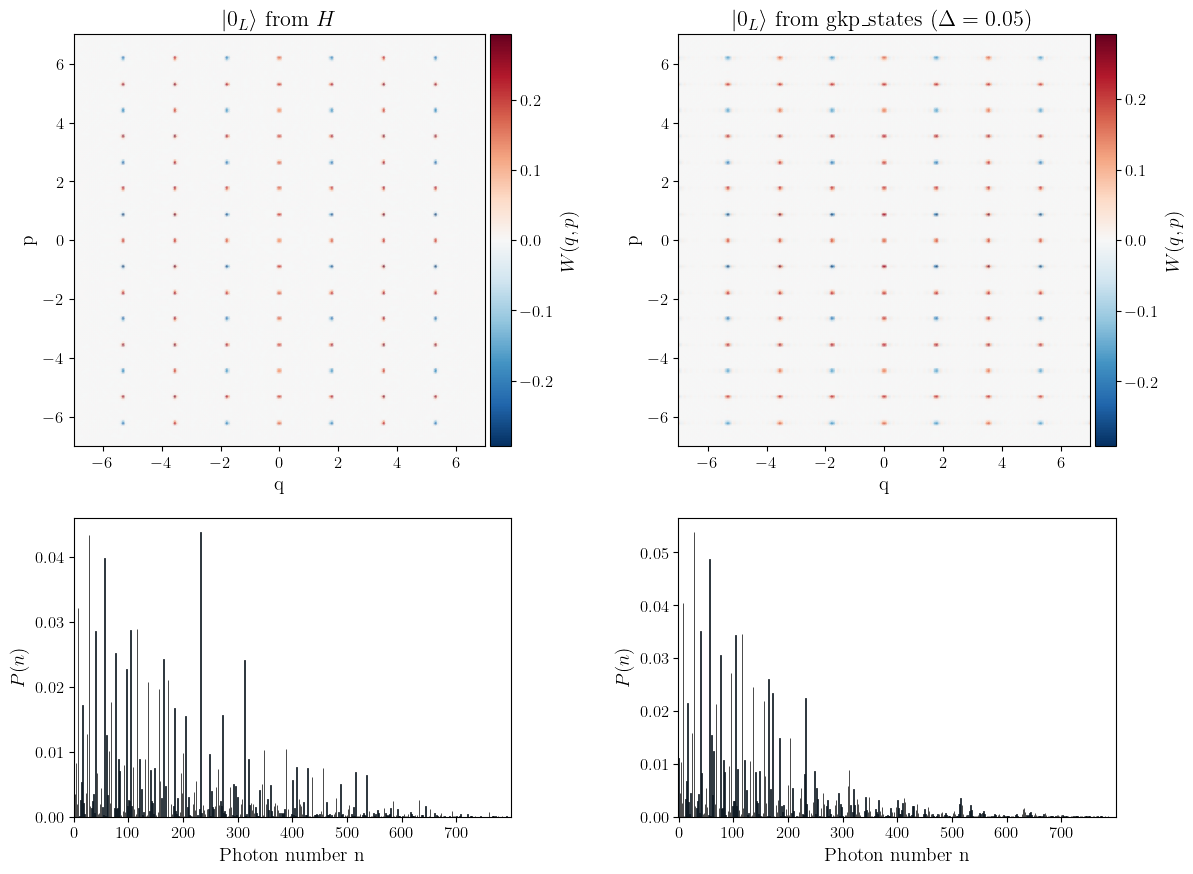

In [56]:
if n_code == 2 and symmetric:
    ref_0, _ = gkp_states(n_fock, gkp_alpha, gkp_beta, best_delta, 10)

    fig, axes = plt.subplots(2, 2, figsize=(12, 9), gridspec_kw={"height_ratios": [1.4, 1]})
    plot_wigner(logical[0], x_bound=bound, y_bound=bound, ax=axes[0, 0], title=r"$\ket{0_L}$ from $H$")
    plot_wigner(ref_0, x_bound=bound, y_bound=bound, ax=axes[0, 1],
                title=rf"$\ket{{0_L}}$ from gkp\_states ($\Delta = {best_delta:.2f}$)")
    plot_photon_number(logical[0], ax=axes[1, 0], max_n=n_fock)
    plot_photon_number(ref_0, ax=axes[1, 1], max_n=n_fock)
    fig.tight_layout(w_pad=4)
    plt.show()